# Preprocessing

In [1]:
import pandas as pd
import numpy as np
import seaborn as sns
import matplotlib.pyplot as plt
from sklearn.preprocessing import StandardScaler
from sklearn.model_selection import train_test_split
from sklearn.linear_model import LogisticRegression

In [2]:
refined_df = pd.read_csv("../data/processed/heart_cleaned.csv")

In [3]:
categorical_columns = ["Sex", "ChestPainType", "RestingECG", "ExerciseAngina", "ST_Slope"]

Creating Dummies using one hot encoding for the categorical columns

In [4]:

df_encode = pd.get_dummies(refined_df, drop_first=True, columns=categorical_columns, dtype=int)
df_encode

,Age,RestingBP,Cholesterol,FastingBS,MaxHR,Oldpeak,HeartDisease,Sex_M,ChestPainType_ATA,ChestPainType_NAP,ChestPainType_TA,RestingECG_Normal,RestingECG_ST,ExerciseAngina_Y,ST_Slope_Flat,ST_Slope_Up
0,40,140,289,0,172,0.00,0,1,1,0,0,1,0,0,0,1
1,49,160,180,0,156,1.00,1,0,0,1,0,1,0,0,1,0
2,37,130,283,0,98,0.00,0,1,1,0,0,0,1,0,0,1
3,48,138,214,0,108,1.50,1,0,0,0,0,1,0,1,1,0
4,54,150,195,0,122,0.00,0,1,0,1,0,1,0,0,0,1
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
4473,51,127,7,1,169,-0.64,1,1,0,0,0,1,0,0,0,1
4474,56,114,0,1,81,-0.98,1,1,0,0,0,0,1,0,0,1
4475,60,154,302,0,164,0.10,1,0,0,0,0,0,0,0,0,1
4476,57,142,274,1,140,-0.08,0,1,1,0,0,1,0,0,0,1


traain test split

In [5]:
X = df_encode.drop("HeartDisease", axis=1)
Y = df_encode["HeartDisease"]


In [6]:
model = LogisticRegression()
X_train, X_test, Y_train, Y_test = train_test_split(X, Y, test_size=0.30, random_state=42, stratify=Y)

In [7]:
from sklearn.preprocessing import StandardScaler
scaler = StandardScaler()
X_train_scaled = scaler.fit_transform(X_train)
X_test_scaled = scaler.transform(X_test)

In [8]:
model.fit(X_train_scaled, Y_train)

,"penalty penalty: {'l1', 'l2', 'elasticnet', None}, default='l2'Specify the norm of the penalty:- `None`: no penalty is added;- `'l2'`: add an L2 penalty term and it is the default choice;- `'l1'`: add an L1 penalty term;- `'elasticnet'`: both L1 and L2 penalty terms are added... warning:: Some penalties may not work with some solvers. See the parameter `solver` below, to know the compatibility between the penalty and solver... versionadded:: 0.19 l1 penalty with SAGA solver (allowing 'multinomial' + L1).. deprecated:: 1.8 `penalty` was deprecated in version 1.8 and will be removed in 1.10. Use `l1_ratio` and `C` instead. `l1_ratio=0` for `penalty='l2'`, `l1_ratio=1` for `penalty='l1'`, `l1_ratio` set to any float between 0 and 1 for `penalty='elasticnet'`, and `C=np.inf` for `penalty=None`.",'deprecated'
,"C C: float, default=1.0Inverse of regularization strength; must be a positive float.Like in support vector machines, smaller values specify strongerregularization. `C=np.inf` results in unpenalized logistic regression.For a visual example on the effect of tuning the `C` parameterwith an L1 penalty, see::ref:`sphx_glr_auto_examples_linear_model_plot_logistic_path.py`.",1.0
,"l1_ratio l1_ratio: float, default=0.0The Elastic-Net mixing parameter, with `0 <= l1_ratio <= 1`. Setting`l1_ratio=1` gives a pure L1-penalty, setting `l1_ratio=0` a pure L2-penalty.Any value between 0 and 1 gives an Elastic-Net penalty of the form`l1_ratio * L1 + (1 - l1_ratio) * L2`... warning:: Certain values of `l1_ratio`, i.e. some penalties, may not work with some solvers. See the parameter `solver` below, to know the compatibility between the penalty and solver... versionchanged:: 1.8 Default value changed from None to 0.0... deprecated:: 1.8 `None` is deprecated and will be removed in version 1.10. Always use `l1_ratio` to specify the penalty type.",0.0
,"dual dual: bool, default=FalseDual (constrained) or primal (regularized, see also:ref:`this equation <regularized-logistic-loss>`) formulation. Dual formulationis only implemented for l2 penalty with liblinear solver. Prefer `dual=False`when n_samples > n_features.",False
,"tol tol: float, default=1e-4Tolerance for stopping criteria.",0.0001
,"fit_intercept fit_intercept: bool, default=TrueSpecifies if a constant (a.k.a. bias or intercept) should beadded to the decision function.",True
,"intercept_scaling intercept_scaling: float, default=1Useful only when the solver `liblinear` is usedand `self.fit_intercept` is set to `True`. In this case, `x` becomes`[x, self.intercept_scaling]`,i.e. a ""synthetic"" feature with constant value equal to`intercept_scaling` is appended to the instance vector.The intercept becomes``intercept_scaling * synthetic_feature_weight``... note:: The synthetic feature weight is subject to L1 or L2 regularization as all other features. To lessen the effect of regularization on synthetic feature weight (and therefore on the intercept) `intercept_scaling` has to be increased.",1
,"class_weight class_weight: dict or 'balanced', default=NoneWeights associated with classes in the form ``{class_label: weight}``.If not given, all classes are supposed to have weight one.The ""balanced"" mode uses the values of y to automatically adjustweights inversely proportional to class frequencies in the input dataas ``n_samples / (n_classes * np.bincount(y))``.Note that these weights will be multiplied with sample_weight (passedthrough the fit method) if sample_weight is specified... versionadded:: 0.17 *class_weight='balanced'*",None
,"random_state random_state: int, RandomState instance, default=NoneOnly used for `solver` == 'sag', 'saga' or 'liblinear' to shuffle thedata. It has no effect on the other solvers.See :term:`Glossary <random_state>` for details.",None
,"solver solver: {'lbfgs', 'liblinear', 'newton-cg', 'newton-cholesky', 'sag', 'saga'}, default='lbfgs'Algorithm to use in the optimization problem. Default is 'lbfgs'.To choose a solver, you might want to consider the following

In [9]:
from sklearn.metrics import r2_score
y_pred = model.predict(X_test_scaled)
# r2 = r2_score(Y_test, y_pred)

n = X_test_scaled.shape[0]
p = X_test_scaled.shape[1]
# r2_adjusted = 1 - ((1-r2) * (n-1) / (n-p-1))
# r2_adjusted
# print(n,p)

In [10]:
from sklearn.metrics import (accuracy_score, roc_auc_score, RocCurveDisplay, confusion_matrix, ConfusionMatrixDisplay, classification_report)
training_score = model.score(X_train_scaled,Y_train) * 100

testing_score = model.score(X_test_scaled, Y_test) * 100

print(f"The training score is : {training_score :.2f}")
print(f"The testing score is : {testing_score :.2f}")

The training score is : 87.62
The testing score is : 87.20


[[512  95]
 [ 77 660]]


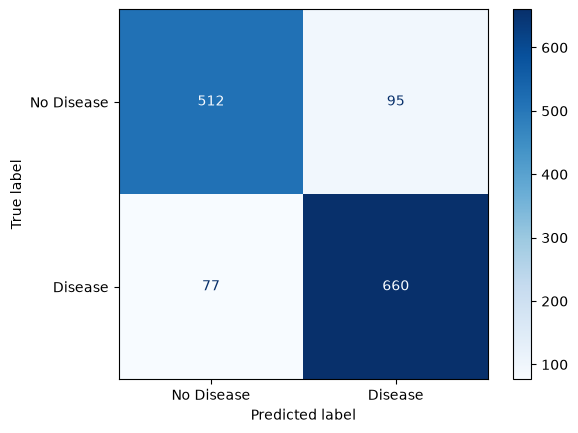

In [11]:
cm = confusion_matrix(Y_test, y_pred)

print(cm)

ConfusionMatrixDisplay(
    confusion_matrix=cm,
    display_labels=["No Disease", "Disease"]
).plot(cmap="Blues")

plt.show()

In [12]:
print(classification_report(
    Y_test,
    y_pred,
    target_names=["No Disease", "Disease"]
))

              precision    recall  f1-score   support

  No Disease       0.87      0.84      0.86       607
     Disease       0.87      0.90      0.88       737

    accuracy                           0.87      1344
   macro avg       0.87      0.87      0.87      1344
weighted avg       0.87      0.87      0.87      1344



ROC-AUC Score: 0.9404996881699039


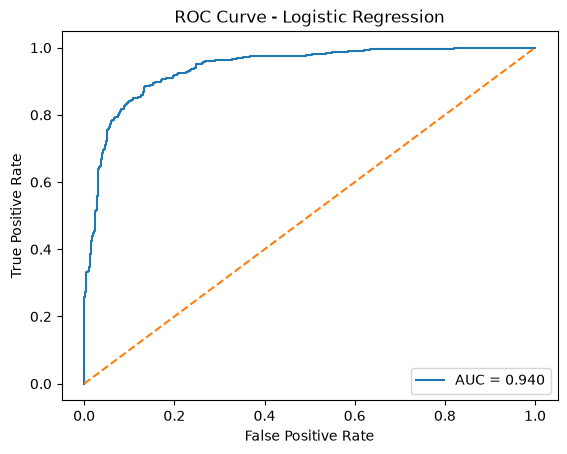

In [15]:
from sklearn.metrics import roc_curve
y_prob = model.predict_proba(X_test_scaled)[:, 1]

# Calculate AUC
auc = roc_auc_score(Y_test, y_prob)

print("ROC-AUC Score:", auc)

# ROC Curve
fpr, tpr, thresholds = roc_curve(Y_test, y_prob)

plt.plot(fpr, tpr, label=f"AUC = {auc:.3f}")
plt.plot([0, 1], [0, 1], linestyle="--")

plt.xlabel("False Positive Rate")
plt.ylabel("True Positive Rate")
plt.title("ROC Curve - Logistic Regression")
plt.legend()
plt.show()

In [14]:
print("Model accuracy:", accuracy_score(
    Y_test, model.predict(X_test_scaled)
))

print("Model score:", model.score(X_test_scaled, Y_test))

print("Confusion matrix:")
print(confusion_matrix(
    Y_test, model.predict(X_test_scaled)
))

Model accuracy: 0.8720238095238095
Model score: 0.8720238095238095
Confusion matrix:
[[512  95]
 [ 77 660]]
